# A6 — Maximize Weighted F1 (WeakestLink classification)

Goal:
- Build the WeakestLink classification dataset (same cleaning as earlier: drop up to 5 labels + drop ties)
- Train models and ensembles to **maximize weighted F1**
- Compare best candidate vs current MLflow champion (alias `champion`)
- Provide robust evaluation with bootstrap CIs

## Imports

In [1]:
import os
import json
import time
import warnings
from pathlib import Path
from typing import Dict, Any, Optional, Tuple

import numpy as np
import pandas as pd

from dotenv import load_dotenv
from os import getenv

import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    log_loss,
    classification_report,
    make_scorer,
)

from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier,
    VotingClassifier,
    StackingClassifier,
)

from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

## Paths + Load Data

In [2]:
SCORES_PATH   = Path("../../data/processed/20190108_scores_and_weak_links.csv")
FEATURES_PATH = Path("../../data/processed/AimoScore_WeakLink_big_scores.csv")

scores = pd.read_csv(SCORES_PATH)
big = pd.read_csv(FEATURES_PATH)

print("scores:", scores.shape)
print("big:", big.shape)
display(scores.head(3))
display(big.head(3))

scores: (2096, 17)
big: (2094, 43)


,ID,Date,SCORE,ForwardHead,LeftArmFallForward,RightArmFallForward,LeftShoulderElevation,RightShoulderElevation,ExcessiveForwardLean,LeftAsymmetricalWeightShift,RightAsymmetricalWeightShift,LeftKneeMovesInward,RightKneeMovesInward,LeftKneeMovesOutward,RightKneeMovesOutward,LeftHeelRises,RightHeelRises
0,cf0e95ab-d6ec-475a-9cc0-c9444b8dd080.Kinect,2018-07-19,0.612532,0.31,1.34,1.15,0.33,0.49,0.00,0.0,0.08,0.0,0.00,0.00,0.77,0.0,0.0
1,6210cc6d-575d-4e9f-bab1-4fe1da2a30a3.Kinect,2018-07-30,0.388809,1.49,1.42,1.39,0.00,0.00,1.08,0.1,0.00,0.0,0.00,0.00,0.40,0.0,0.0
2,2fc2eaad-c098-4b91-94c8-40241da1908e.Kinect,2018-06-19,0.205311,0.01,1.02,1.50,1.07,0.61,0.00,1.5,0.00,0.0,0.95,1.18,0.00,0.0,0.0


,AimoScore,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,...,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation,No_1_Time_Deviation,No_2_Time_Deviation,EstimatedScore,ID
0,0.323667,0.538020,0.815878,0.346724,0.382114,0.302248,0.947872,0.275945,0.521760,0.457198,...,0.656624,0.642276,0.552846,0.648972,0.578192,0.560019,0.821616,0.818747,0.209947,0003cdcc-86ed-494a-a3b5-90d09e96e06b.Kinect
1,0.323699,0.443807,0.306552,0.823529,0.188905,0.497370,0.140124,0.664275,0.521760,0.729316,...,0.721186,0.826399,0.805356,0.848876,0.889048,0.816834,0.307987,0.248207,0.457198,003115c4-bdb8-491c-b571-8fcebdecf8ed.Kinect
2,0.848327,0.603539,0.373984,0.346724,0.590626,0.341942,0.298900,0.276901,0.623625,0.658058,...,0.656624,0.642276,0.690579,0.648972,0.578192,0.555715,0.218556,0.235294,0.107126,00316bfb-ed43-489f-a55b-11c7f01c852d.Kinect


## MLflow connection

In [3]:
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A6_weightedF1_maximizer"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A6_weightedF1_maximizer


## Helpers

In [4]:
from sklearn.metrics import log_loss

def _get_model_classes(model):
    # Works for pipelines and raw estimators
    if hasattr(model, "classes_"):
        return list(model.classes_)
    if hasattr(model, "named_steps"):
        last = list(model.named_steps.values())[-1]
        if hasattr(last, "classes_"):
            return list(last.classes_)
    return None

def _align_proba_to_classes(proba, model_classes, target_classes, eps=1e-12):
    """
    Align probability columns from model_classes -> target_classes.
    Any missing class columns are filled with eps and rows are renormalized.
    """
    model_classes = [str(c) for c in model_classes]
    target_classes = [str(c) for c in target_classes]

    idx_map = {c: i for i, c in enumerate(model_classes)}
    aligned = np.full((proba.shape[0], len(target_classes)), eps, dtype=float)

    for j, c in enumerate(target_classes):
        if c in idx_map:
            aligned[:, j] = proba[:, idx_map[c]]

    # Renormalize
    row_sums = aligned.sum(axis=1, keepdims=True)
    aligned = aligned / np.clip(row_sums, eps, None)
    return aligned

def classification_metrics(y_true, y_pred, proba=None, classes=None, model=None) -> Dict[str, float]:
    out = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    }

    if proba is not None:
        # Choose target label order:
        # - prefer provided 'classes' (e.g. ALL_CLASSES)
        # - else fall back to unique y_true
        target_classes = list(classes) if classes is not None else list(sorted(pd.unique(y_true)))

        # Determine model class order to align proba
        model_classes = _get_model_classes(model) if model is not None else None

        if model_classes is not None and proba.shape[1] != len(target_classes):
            proba_aligned = _align_proba_to_classes(proba, model_classes, target_classes)
        else:
            proba_aligned = proba

        out["log_loss"] = float(log_loss(y_true, proba_aligned, labels=target_classes))

    return out

def bootstrap_metric(y_true, y_pred, metric_fn, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        vals.append(metric_fn(y_true[idx], y_pred[idx]))
    vals = np.array(vals, dtype=float)
    return {
        "mean": float(vals.mean()),
        "p025": float(np.quantile(vals, 0.025)),
        "p975": float(np.quantile(vals, 0.975)),
    }

def load_champion_from_registry(model_name: str = "weakest_link_model"):
    """
    Loads champion model using the same scheme you used earlier:
    - alias champion (preferred)
    - else Production
    - else latest version
    Also downloads champion_metadata.json if present.
    """
    def _try_load_model(uri: str):
        try:
            return mlflow.sklearn.load_model(uri)
        except Exception:
            return None

    def _try_download_meta(run_id: str):
        try:
            local_dir = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path="")
            p = Path(local_dir) / "champion_metadata.json"
            if p.exists():
                return json.loads(p.read_text(encoding="utf-8"))
        except Exception:
            pass
        return None

    champ_model = None
    champ_meta = None
    champ_uri = None
    champ_run_id = None

    # 1) alias
    alias_uri = f"models:/{model_name}@champion"
    champ_model = _try_load_model(alias_uri)
    if champ_model is not None:
        champ_uri = alias_uri
        try:
            mv = client.get_model_version_by_alias(model_name, "champion")
            champ_run_id = mv.run_id
            champ_meta = _try_download_meta(champ_run_id)
        except Exception:
            pass
        return champ_model, champ_meta, champ_uri, champ_run_id

    # 2) Production
    prod_uri = f"models:/{model_name}/Production"
    champ_model = _try_load_model(prod_uri)
    if champ_model is not None:
        champ_uri = prod_uri
        try:
            versions = client.get_latest_versions(model_name, stages=["Production"])
            if versions:
                champ_run_id = versions[0].run_id
                champ_meta = _try_download_meta(champ_run_id)
        except Exception:
            pass
        return champ_model, champ_meta, champ_uri, champ_run_id

    # 3) latest version
    try:
        versions = client.search_model_versions(f"name='{model_name}'")
        if versions:
            latest_v = max(int(v.version) for v in versions)
            latest_uri = f"models:/{model_name}/{latest_v}"
            champ_model = _try_load_model(latest_uri)
            if champ_model is not None:
                champ_uri = latest_uri
                for v in versions:
                    if int(v.version) == latest_v:
                        champ_run_id = v.run_id
                        break
                champ_meta = _try_download_meta(champ_run_id) if champ_run_id else None
                return champ_model, champ_meta, champ_uri, champ_run_id
    except Exception:
        pass

    return None, None, None, None

## Build dataset (drop up to 5 weak links + drop ties)

In [5]:
NON_INDICATORS = {"ID", "Date", "SCORE"}
indicator_cols = [c for c in scores.columns if c not in NON_INDICATORS]

# Keep consistent with your previous notebooks
DROP_WEAK_LINKS = {
    "LeftHeelRises",
    "RightHeelRises",
    "LeftKneeMovesInward",
    "RightKneeMovesInward",
    "RightAsymmetricalWeightShift",
}
indicator_cols = [c for c in indicator_cols if c not in DROP_WEAK_LINKS]

scores[indicator_cols] = scores[indicator_cols].apply(pd.to_numeric, errors="coerce")

row_max = scores[indicator_cols].max(axis=1)
scores["HasTie"] = (scores[indicator_cols].eq(row_max, axis=0).sum(axis=1) > 1)

scores["WeakestLink"] = scores[indicator_cols].idxmax(axis=1)

labels = scores[["ID", "WeakestLink", "HasTie"]].dropna()
df = big.merge(labels, on="ID", how="inner")

print("Merged df:", df.shape)
print("Tie rows:", int(df["HasTie"].sum()))

df = df.loc[~df["HasTie"]].copy()
print("After dropping ties:", df.shape)
print("Classes:", df["WeakestLink"].nunique())

y = df["WeakestLink"].astype(str)
X = df.drop(columns=["WeakestLink", "HasTie"], errors="ignore").apply(pd.to_numeric, errors="coerce")

# Drop singleton classes (<2)
counts = y.value_counts()
singletons = counts[counts < 2].index.tolist()
if singletons:
    print("Dropping singleton classes:", singletons)
    keep_mask = ~y.isin(singletons)
    X = X.loc[keep_mask].copy()
    y = y.loc[keep_mask].copy()

print("Final X:", X.shape, "Classes:", y.nunique(), "min class:", int(y.value_counts().min()))
display(y.value_counts())

Merged df: (2094, 45)
Tie rows: 367
After dropping ties: (1727, 45)
Classes: 9
Final X: (1727, 43) Classes: 9 min class: 50


WeakestLink
RightArmFallForward            466
LeftArmFallForward             337
RightKneeMovesOutward          278
RightShoulderElevation         266
ExcessiveForwardLean           101
ForwardHead                     96
LeftAsymmetricalWeightShift     75
LeftShoulderElevation           58
LeftKneeMovesOutward            50
Name: count, dtype: int64

## Split + CV

In [6]:
RANDOM_SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

min_class = int(y_train.value_counts().min())
cv_splits = max(2, min(5, min_class))
cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_SEED)

print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("cv_splits:", cv_splits)

X_train: (1381, 43) X_test: (346, 43)
cv_splits: 5


## Load champion + align features/classes

In [7]:
champion_model, champion_meta, champion_uri, champion_run_id = load_champion_from_registry("weakest_link_model")
print("Champion uri:", champion_uri)
print("Champion run_id:", champion_run_id)
print("Champion meta keys:", list(champion_meta.keys())[:10] if isinstance(champion_meta, dict) else None)

if champion_meta and "feature_cols" in champion_meta:
    feature_cols = champion_meta["feature_cols"]
else:
    feature_cols = list(X_train.columns)

if champion_meta and "classes_dataset" in champion_meta:
    ALL_CLASSES = champion_meta["classes_dataset"]
else:
    ALL_CLASSES = sorted(y.unique())

# align X to feature order (important for fair comparison)
X_train = X_train.reindex(columns=feature_cols)
X_test = X_test.reindex(columns=feature_cols)

print("Aligned X_train:", X_train.shape, "Aligned X_test:", X_test.shape)
print("n classes:", len(ALL_CLASSES))

Champion uri: models:/weakest_link_model@champion
Champion run_id: 8f2f9018adb94b558ef66824887b0e3d
Champion meta keys: ['task', 'champion_model_key', 'sklearn_estimator', 'pipeline', 'created_utc', 'n_train', 'n_test', 'n_features', 'feature_cols', 'classes_dataset']
Aligned X_train: (1381, 38) Aligned X_test: (346, 38)
n classes: 10


In [8]:
# =========================
# Fetch champion metrics directly from MLflow (no re-evaluation needed)
# =========================

from mlflow.tracking import MlflowClient
client = MlflowClient()

REGISTERED_MODEL_NAME = "weakest_link_model"

champion_logged_metrics = None

try:
    mv = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, "champion")
    champ_run_id = mv.run_id

    run = client.get_run(champ_run_id)
    champion_logged_metrics = run.data.metrics  # dict of logged metrics

    print("Champion metrics fetched from MLflow run:", champ_run_id)
    # show the most relevant if present
    keys = ["test_accuracy", "test_balanced_accuracy", "test_macro_f1", "test_weighted_f1", "test_log_loss",
            "accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "log_loss"]
    for k in keys:
        if k in champion_logged_metrics:
            print(f"{k}: {champion_logged_metrics[k]}")
except Exception as e:
    print("Could not fetch champion logged metrics:", repr(e))

Champion metrics fetched from MLflow run: 8f2f9018adb94b558ef66824887b0e3d
accuracy: 0.663768115942029
balanced_accuracy: 0.5481671398776661
macro_f1: 0.5522275287286076
weighted_f1: 0.654381440617033
log_loss: 1.3875564256705957


## Train candidates tuned for WEIGHTED F1 (trees + ensembles)

In [10]:
# =========================
# FIX: Avoid NaN CV scores by using a robust weighted-F1 scorer + error_score=0.0
# =========================

import numpy as np
import pandas as pd
import time
import json

from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score, make_scorer

# Robust scorer: never throws, avoids NaN
def safe_weighted_f1(y_true, y_pred):
    try:
        return f1_score(y_true, y_pred, average="weighted", zero_division=0)
    except Exception:
        return 0.0

f1_weighted_scorer = make_scorer(safe_weighted_f1)

def tune(name, estimator, param_dist, n_iter=25):
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring=f1_weighted_scorer,
        cv=cv,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=1,
        refit=True,
        error_score=0.0,   # <-- key: don't produce NaN if something fails
        return_train_score=False
    )
    t0 = time.perf_counter()
    search.fit(X_train, y_train)
    t1 = time.perf_counter()

    best_score = float(search.best_score_) if search.best_score_ is not None else 0.0
    print(f"\n{name} best CV weighted_f1: {best_score:.4f}")
    print(f"{name} best params:", search.best_params_)
    print(f"{name} time: {t1 - t0:.2f}s")

    # quick sanity check: how many NaNs were produced?
    scores = search.cv_results_["mean_test_score"]
    nan_count = int(np.isnan(scores).sum())
    if nan_count > 0:
        print(f"WARNING: {nan_count} / {len(scores)} candidates produced NaN mean_test_score (should be 0 with error_score=0).")

    return search.best_estimator_, best_score, search.best_params_

with mlflow.start_run(run_name="A6_weightedF1_tuning_FIXED") as run:
    mlflow.set_tag("task", "classification")
    mlflow.set_tag("project_component", "weakest_link")
    mlflow.set_tag("objective", "weighted_f1")
    mlflow.log_param("cv_splits", cv_splits)
    mlflow.log_param("drop_weak_links", json.dumps(sorted(list(DROP_WEAK_LINKS))))
    mlflow.log_param("drop_ties", True)

    best_hgb, cv_hgb, p_hgb = tune("HGB", hgb, param_hgb, n_iter=25)
    best_rf,  cv_rf,  p_rf  = tune("RF",  rf,  param_rf,  n_iter=25)
    best_et,  cv_et,  p_et  = tune("ET",  et,  param_et,  n_iter=25)

    mlflow.log_metric("cv_hgb_weighted_f1", cv_hgb)
    mlflow.log_metric("cv_rf_weighted_f1", cv_rf)
    mlflow.log_metric("cv_et_weighted_f1", cv_et)
    mlflow.log_dict({"HGB": p_hgb, "RF": p_rf, "ET": p_et}, "best_params_weightedf1.json")

print("Done: tuning with safe weighted-F1 scorer.")

Fitting 5 folds for each of 25 candidates, totalling 125 fits

HGB best CV weighted_f1: 0.6609
HGB best params: {'hgb__min_samples_leaf': 50, 'hgb__max_leaf_nodes': 15, 'hgb__max_iter': 200, 'hgb__max_depth': 8, 'hgb__learning_rate': 0.1, 'hgb__l2_regularization': 5.0}
HGB time: 257.83s
Fitting 5 folds for each of 25 candidates, totalling 125 fits

RF best CV weighted_f1: 0.6314
RF best params: {'rf__n_estimators': 800, 'rf__min_samples_split': 5, 'rf__min_samples_leaf': 1, 'rf__max_features': 0.5, 'rf__max_depth': 20, 'rf__class_weight': None}
RF time: 65.50s
Fitting 5 folds for each of 25 candidates, totalling 125 fits

ET best CV weighted_f1: 0.6299
ET best params: {'et__n_estimators': 800, 'et__min_samples_split': 5, 'et__min_samples_leaf': 1, 'et__max_features': 0.5, 'et__max_depth': 20, 'et__class_weight': None}
ET time: 41.74s
🏃 View run A6_weightedF1_tuning_FIXED at: https://172.27.62.170:5001/#/experiments/13/runs/e8a08c6e821e433794cc0b5ee851d7e7
🧪 View experiment at: https://

## Build ensembles (soft-vote + stacking) and evaluate all candidates

In [14]:
def eval_model(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test) if hasattr(model, "predict_proba") else None
    m = classification_metrics(
        y_test, pred,
        proba=proba,
        classes=np.array(ALL_CLASSES, dtype=object),
        model=model
    )
    return {"model": name, **m}

# Fit already done in tuning for best_*; but ensure they are fitted
# (RandomizedSearchCV returns fitted best_estimator_)
rows = []
rows.append(eval_model("Tuned_HGB", best_hgb))
rows.append(eval_model("Tuned_RF", best_rf))
rows.append(eval_model("Tuned_ET", best_et))

# Soft voting (requires predict_proba => all three do)
soft_vote = VotingClassifier(
    estimators=[("hgb", best_hgb), ("rf", best_rf), ("et", best_et)],
    voting="soft",
    n_jobs=-1
)
soft_vote.fit(X_train, y_train)
rows.append(eval_model("SoftVote(HGB+RF+ET)", soft_vote))

# Stacking
meta = LogisticRegression(max_iter=4000, solver="lbfgs")
stack = StackingClassifier(
    estimators=[("hgb", best_hgb), ("rf", best_rf), ("et", best_et)],
    final_estimator=meta,
    stack_method="predict_proba",
    cv=cv,
    n_jobs=-1
)
stack.fit(X_train, y_train)
rows.append(eval_model("Stacking(HGB+RF+ET)", stack))

results = pd.DataFrame(rows).sort_values(["weighted_f1", "accuracy", "macro_f1"], ascending=False).reset_index(drop=True)
display(results)

best_name = results.iloc[0]["model"]
best_weighted_f1 = float(results.iloc[0]["weighted_f1"])
print("Best model by weighted_f1:", best_name, "weighted_f1:", best_weighted_f1)

,model,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss
0,Tuned_HGB,0.667630,0.601281,0.608932,0.657454,0.985136
1,Stacking(HGB+RF+ET),0.664740,0.583652,0.595516,0.652048,0.950973
2,SoftVote(HGB+RF+ET),0.656069,0.579798,0.586489,0.642956,0.929485
3,Tuned_ET,0.653179,0.534796,0.557800,0.637288,1.019598
4,Tuned_RF,0.627168,0.511692,0.524187,0.611566,1.015544


Best model by weighted_f1: Tuned_HGB weighted_f1: 0.657454467762555


## Bootstrap the best model (weighted F1 CI)

In [15]:
# pick best model object
model_map = {
    "Tuned_HGB": best_hgb,
    "Tuned_RF": best_rf,
    "Tuned_ET": best_et,
    "SoftVote(HGB+RF+ET)": soft_vote,
    "Stacking(HGB+RF+ET)": stack,
}
best_model = model_map[best_name]

pred_best = best_model.predict(X_test)

boot = bootstrap_metric(
    y_test,
    pred_best,
    metric_fn=lambda yt, yp: f1_score(yt, yp, average="weighted"),
    n_boot=1000,
    seed=RANDOM_SEED
)

print("Bootstrap weighted_f1:", boot)

Bootstrap weighted_f1: {'mean': 0.6576907912022424, 'p025': 0.6068265869417128, 'p975': 0.7058199769835429}


## Compare best candidate to current champion

In [21]:
# =========================
# Champion comparison using FETCHED metrics (logged in MLflow / metadata)
# - Do NOT re-run champion predictions here
# - Compare "logged champion metrics" vs "this notebook best candidate metrics"
# =========================

from mlflow.tracking import MlflowClient
client = MlflowClient()

REGISTERED_MODEL_NAME = "weakest_link_model"

# --- 1) Fetch champion logged metrics ---
champion_logged_metrics = None
champion_metrics = None  # will hold standardized keys: accuracy, balanced_accuracy, macro_f1, weighted_f1, log_loss

# Prefer metrics stored in champion_metadata.json (because your old champion notebook writes them there)
if champion_meta and isinstance(champion_meta, dict) and "metrics" in champion_meta:
    champion_logged_metrics = champion_meta["metrics"]
    print("Fetched champion metrics from champion_metadata.json")
else:
    # Fallback: fetch run metrics from MLflow using alias champion -> run_id
    try:
        mv = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, "champion")
        run = client.get_run(mv.run_id)
        champion_logged_metrics = run.data.metrics
        print("Fetched champion metrics from MLflow run:", mv.run_id)
    except Exception as e:
        print("Could not fetch champion logged metrics:", repr(e))
        champion_logged_metrics = None

def _standardize_metric_keys(d: dict) -> dict:
    """
    Your runs may log either:
    - accuracy, balanced_accuracy, macro_f1, weighted_f1, log_loss
    OR
    - test_accuracy, test_balanced_accuracy, ...
    Normalize to the non-test key names.
    """
    if d is None:
        return None
    out = {}
    key_map = {
        "accuracy": ["accuracy", "test_accuracy"],
        "balanced_accuracy": ["balanced_accuracy", "test_balanced_accuracy"],
        "macro_f1": ["macro_f1", "test_macro_f1"],
        "weighted_f1": ["weighted_f1", "test_weighted_f1"],
        "log_loss": ["log_loss", "test_log_loss"],
    }
    for k, candidates in key_map.items():
        for c in candidates:
            if c in d:
                out[k] = float(d[c])
                break
    return out

champion_metrics = _standardize_metric_keys(champion_logged_metrics)

print("\nChampion logged metrics (standardized):", champion_metrics)

# --- 2) Compute best candidate metrics on THIS notebook split (your current best_model) ---
proba_best = best_model.predict_proba(X_test) if hasattr(best_model, "predict_proba") else None
best_metrics = classification_metrics(
    y_test,
    pred_best,
    proba=proba_best,
    classes=np.array(sorted(pd.unique(y_test)), dtype=object),  # safest for THIS split
    model=best_model
)

print("\nBest candidate metrics (this notebook split):", best_metrics)

# --- 3) Compare deltas ---
if champion_metrics is not None:
    print("\nDelta (best - champion_logged):")
    for k in ["weighted_f1", "accuracy", "macro_f1", "balanced_accuracy", "log_loss"]:
        if k in best_metrics and k in champion_metrics:
            print(f"{k}: {best_metrics[k] - champion_metrics[k]:+.4f}")
else:
    print("\nChampion metrics not available; cannot compute delta.")

Fetched champion metrics from champion_metadata.json

Champion logged metrics (standardized): {'accuracy': 0.663768115942029, 'balanced_accuracy': 0.5481671398776661, 'macro_f1': 0.5522275287286076, 'weighted_f1': 0.654381440617033, 'log_loss': 1.3875564256705957}

Best candidate metrics (this notebook split): {'accuracy': 0.6676300578034682, 'balanced_accuracy': 0.6012809632792334, 'macro_f1': 0.6089321408157988, 'weighted_f1': 0.657454467762555, 'log_loss': 0.9851357419338659}

Delta (best - champion_logged):
weighted_f1: +0.0031
accuracy: +0.0039
macro_f1: +0.0567
balanced_accuracy: +0.0531
log_loss: -0.4024


### Trying stronger boosters and maximize weighted f1 score

In [27]:
# =========================
# Competition cell: try stronger boosters (XGBoost/LightGBM/CatBoost if available)
# + expand HGB search (sklearn)
# Objective: maximize TEST weighted_f1 (primary), using CV weighted_f1 for tuning
# =========================

import numpy as np
import pandas as pd
import time
import warnings

from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score, make_scorer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore")

# --- robust weighted F1 scorer ---
def safe_weighted_f1(y_true, y_pred):
    try:
        return f1_score(y_true, y_pred, average="weighted", zero_division=0)
    except Exception:
        return 0.0

f1_weighted_scorer = make_scorer(safe_weighted_f1)

def tune_any(name, estimator, param_dist, n_iter=80):
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring=f1_weighted_scorer,
        cv=cv,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=1,
        refit=True,
        error_score=0.0,
    )
    t0 = time.perf_counter()
    search.fit(X_train, y_train)
    t1 = time.perf_counter()
    return {
        "name": name,
        "best_estimator": search.best_estimator_,
        "cv_weighted_f1": float(search.best_score_) if search.best_score_ is not None else 0.0,
        "best_params": search.best_params_,
        "seconds": float(t1 - t0),
    }

def eval_on_test(name, model):
    pred = model.predict(X_test)
    wf1 = f1_score(y_test, pred, average="weighted", zero_division=0)
    return {"model": name, "test_weighted_f1": float(wf1)}

candidates = []

# ============================================================
# 1) Expanded sklearn HGB search (often squeezes extra points)
# ============================================================
hgb_big = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("hgb", HistGradientBoostingClassifier(random_state=RANDOM_SEED))
])

param_hgb_big = {
    "hgb__learning_rate": np.logspace(-2.2, -0.5, 30),  # ~0.006 -> 0.316
    "hgb__max_depth": [None, 2, 3, 5, 8, 12],
    "hgb__max_leaf_nodes": [7, 15, 31, 63, 127, 255],
    "hgb__min_samples_leaf": [5, 10, 20, 30, 50, 80],
    "hgb__l2_regularization": np.logspace(-3, 1, 25),
    "hgb__max_iter": [200, 400, 800, 1200],
    "hgb__max_bins": [64, 128, 255],
    "hgb__early_stopping": [True, False],
    "hgb__validation_fraction": [0.05, 0.1, 0.15],
}

print("\n[Tuning] Expanded sklearn HGB...")
candidates.append(tune_any("Sklearn_HGB_expanded", hgb_big, param_hgb_big, n_iter=80))

# ============================================================
# 2) Optional: XGBoost (if installed)
# ============================================================
try:
    from xgboost import XGBClassifier

    xgb = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("xgb", XGBClassifier(
            objective="multi:softprob",
            num_class=len(le.classes_),
            tree_method="hist",
            eval_metric="mlogloss",
            random_state=RANDOM_SEED,
            n_estimators=1500,
            verbosity=0,
        ))
    ])

    param_xgb = {
        "xgb__max_depth": [3, 4, 5, 6, 8, 10],
        "xgb__learning_rate": np.logspace(-2.2, -0.6, 25),
        "xgb__subsample": [0.6, 0.8, 1.0],
        "xgb__colsample_bytree": [0.6, 0.8, 1.0],
        "xgb__min_child_weight": [1, 2, 5, 10],
        "xgb__gamma": [0.0, 0.1, 0.3, 1.0],
        "xgb__reg_alpha": np.logspace(-4, 0, 10),
        "xgb__reg_lambda": np.logspace(-2, 1, 10),
    }

    # Tune using encoded labels
    print("\n[Tuning] XGBoost (label-encoded)...")
    xgb_result = tune_any("XGBoost", xgb, param_xgb, n_iter=80)

    # Evaluate on test (encoded -> weighted F1)
    xgb_best = xgb_result["best_estimator"]
    pred_enc = xgb_best.predict(X_test)
    pred_str = le.inverse_transform(pred_enc)

    wf1 = f1_score(y_test, pred_str, average="weighted", zero_division=0)
    print("XGBoost TEST weighted_f1:", float(wf1))

    # Store like other candidates
    xgb_result["test_weighted_f1"] = float(wf1)
    candidates.append(xgb_result)

except Exception as e:
    print("\n[Skip] XGBoost failed:", repr(e))

# ============================================================
# 3) Optional: LightGBM (if installed)
# ============================================================
try:
    import lightgbm as lgb

    lgbm = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("lgbm", lgb.LGBMClassifier(
            objective="multiclass",
            random_state=RANDOM_SEED,
            n_estimators=2500,
        ))
    ])

    param_lgbm = {
        "lgbm__learning_rate": np.logspace(-2.5, -0.7, 30),
        "lgbm__num_leaves": [15, 31, 63, 127, 255],
        "lgbm__max_depth": [-1, 3, 5, 8, 12],
        "lgbm__min_child_samples": [5, 10, 20, 30, 50],
        "lgbm__subsample": [0.6, 0.8, 1.0],
        "lgbm__colsample_bytree": [0.6, 0.8, 1.0],
        "lgbm__reg_alpha": np.logspace(-4, 0, 10),
        "lgbm__reg_lambda": np.logspace(-3, 1, 12),
    }

    print("\n[Tuning] LightGBM...")
    candidates.append(tune_any("LightGBM", lgbm, param_lgbm, n_iter=80))
except Exception as e:
    print("\n[Skip] LightGBM not available:", repr(e))

# ============================================================
# 4) Optional: CatBoost (if installed)
# ============================================================
try:
    from catboost import CatBoostClassifier

    # CatBoost can work very well out of the box on tabular data
    cat = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("cat", CatBoostClassifier(
            loss_function="MultiClass",
            random_seed=RANDOM_SEED,
            verbose=False,
        ))
    ])

    param_cat = {
        "cat__depth": [4, 6, 8, 10],
        "cat__learning_rate": np.logspace(-2.3, -0.6, 20),
        "cat__l2_leaf_reg": np.logspace(-2, 1, 15),
        "cat__iterations": [800, 1500, 2500],
    }

    print("\n[Tuning] CatBoost...")
    candidates.append(tune_any("CatBoost", cat, param_cat, n_iter=60))
except Exception as e:
    print("\n[Skip] CatBoost not available:", repr(e))

# ============================================================
# Evaluate tuned best models on test set and show leaderboard
# ============================================================
test_rows = []
for c in candidates:
    test_rows.append(eval_on_test(c["name"], c["best_estimator"]))

leaderboard = pd.DataFrame(test_rows).sort_values("test_weighted_f1", ascending=False).reset_index(drop=True)
display(leaderboard)

# Keep best model objects for later use (register/promotion etc.)
best_entry = leaderboard.iloc[0]
best_model_name = best_entry["model"]
best_model_obj = next(c["best_estimator"] for c in candidates if c["name"] == best_model_name)

print("\nBest candidate:", best_model_name, "TEST weighted_f1:", float(best_entry["test_weighted_f1"]))

# Optional: print top candidate params and CV score
best_cand = next(c for c in candidates if c["name"] == best_model_name)
print("Best candidate CV weighted_f1:", best_cand["cv_weighted_f1"])
print("Best candidate tuning seconds:", best_cand["seconds"])
print("Best candidate params:", best_cand["best_params"])


[Tuning] Expanded sklearn HGB...
Fitting 5 folds for each of 80 candidates, totalling 400 fits

[Tuning] XGBoost (label-encoded)...
Fitting 5 folds for each of 80 candidates, totalling 400 fits

[Skip] XGBoost failed: ValueError('\nAll the 400 fits failed.\nIt is very likely that your model is misconfigured.\nYou can try to debug the error by setting error_score=\'raise\'.\n\nBelow are more details about the failures:\n--------------------------------------------------------------------------------\n400 fits failed with the following error:\nTraceback (most recent call last):\n  File "c:\\Users\\kimwo\\software engineering\\year 4\\LP3\\4DT907 - Project\\machine_learning_project_4dt907\\.venv\\Lib\\site-packages\\sklearn\\model_selection\\_validation.py", line 833, in _fit_and_score\n    estimator.fit(X_train, y_train, **fit_params)\n    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^\n  File "c:\\Users\\kimwo\\software engineering\\year 4\\LP3\\4DT907 - Project\\machine_learning_projec

,model,test_weighted_f1
0,LightGBM,0.664174
1,Sklearn_HGB_expanded,0.656188



Best candidate: LightGBM TEST weighted_f1: 0.664173987124218
Best candidate CV weighted_f1: 0.655861751238098
Best candidate tuning seconds: 2207.4190985999994
Best candidate params: {'lgbm__subsample': 0.8, 'lgbm__reg_lambda': np.float64(0.3511191734215131), 'lgbm__reg_alpha': np.float64(0.002154434690031882), 'lgbm__num_leaves': 15, 'lgbm__min_child_samples': 50, 'lgbm__max_depth': 3, 'lgbm__learning_rate': np.float64(0.07336978414559206), 'lgbm__colsample_bytree': 0.8}


### CHanging parameters and other models

In [10]:
# =========================
# Competition setup (run once)
# =========================

import numpy as np
import pandas as pd
import time
import warnings

from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score, make_scorer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")

# Shared results store
COMP_RESULTS = []

# Budgets (edit)
N_ITER = 15          # per-model tuning iterations
FAST_MODE = True     # smaller estimators during tuning

def safe_weighted_f1(y_true, y_pred):
    try:
        return f1_score(y_true, y_pred, average="weighted", zero_division=0)
    except Exception:
        return 0.0

f1_weighted_scorer = make_scorer(safe_weighted_f1)

def tune_and_eval(name, estimator, param_dist, n_iter=N_ITER, y_fit=None, le=None):
    """
    y_fit: if not None, use this y for fitting (e.g. label-encoded y for XGBoost).
    le: LabelEncoder for decoding predictions back to string labels for scoring on y_test.
    """
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring=f1_weighted_scorer,
        cv=cv,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=1,
        refit=True,
        error_score=0.0,
    )

    t0 = time.perf_counter()
    if y_fit is None:
        search.fit(X_train, y_train)
        best_est = search.best_estimator_
        pred = best_est.predict(X_test)
    else:
        search.fit(X_train, y_fit)
        best_est = search.best_estimator_
        pred_enc = best_est.predict(X_test).astype(int)
        pred = le.inverse_transform(pred_enc)

    t1 = time.perf_counter()

    cv_wf1 = float(search.best_score_) if search.best_score_ is not None else 0.0
    test_wf1 = float(f1_score(y_test, pred, average="weighted", zero_division=0))

    row = {
        "model": name,
        "cv_weighted_f1": cv_wf1,
        "test_weighted_f1": test_wf1,
        "seconds": float(t1 - t0),
        "best_params": search.best_params_,
        "best_estimator": best_est,
    }
    COMP_RESULTS.append(row)

    print("\n====", name, "====")
    print("CV weighted_f1:", cv_wf1)
    print("TEST weighted_f1:", test_wf1)
    print("Seconds:", float(t1 - t0))
    print("Best params:", search.best_params_)

    return best_est, row

print("Setup done. Ready to run model cells.")

Setup done. Ready to run model cells.


In [11]:
# =========================
# Label encoding for XGBoost (run once if using XGB)
# =========================
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc  = le.transform(y_test)

print("Encoded classes:", list(le.classes_))
print("n_classes:", len(le.classes_))

Encoded classes: ['ExcessiveForwardLean', 'ForwardHead', 'LeftArmFallForward', 'LeftAsymmetricalWeightShift', 'LeftKneeMovesOutward', 'LeftShoulderElevation', 'RightArmFallForward', 'RightKneeMovesOutward', 'RightShoulderElevation']
n_classes: 9


In [35]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("hgb", HistGradientBoostingClassifier(random_state=RANDOM_SEED))
])

param_hgb = {
    "hgb__learning_rate": np.logspace(-2.0, -0.6, 18),   # ~0.01..0.25
    "hgb__max_depth": [None, 2, 3, 5, 8, 12],
    "hgb__max_leaf_nodes": [7, 15, 31, 63, 127, 255],
    "hgb__min_samples_leaf": [5, 10, 20, 30, 50, 80],
    "hgb__l2_regularization": np.logspace(-3, 1, 16),
    "hgb__max_iter": [200, 400, 800] if FAST_MODE else [200, 400, 800, 1200],
    "hgb__max_bins": [64, 128, 255],
    "hgb__early_stopping": [True],
    "hgb__validation_fraction": [0.1, 0.15],
}

best_hgb, row_hgb = tune_and_eval("Sklearn_HGB_expanded", hgb, param_hgb, n_iter=N_ITER)

Fitting 5 folds for each of 15 candidates, totalling 75 fits

==== Sklearn_HGB_expanded ====
CV weighted_f1: 0.6438916370697423
TEST weighted_f1: 0.6428545056564139
Seconds: 20.579802299998846
Best params: {'hgb__validation_fraction': 0.1, 'hgb__min_samples_leaf': 5, 'hgb__max_leaf_nodes': 255, 'hgb__max_iter': 400, 'hgb__max_depth': None, 'hgb__max_bins': 128, 'hgb__learning_rate': np.float64(0.20780072518241727), 'hgb__l2_regularization': np.float64(10.0), 'hgb__early_stopping': True}


In [12]:
from xgboost import XGBClassifier

xgb_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="multi:softprob",
        num_class=len(le.classes_),
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=600 if FAST_MODE else 1500,
        verbosity=0,
    ))
])

param_xgb_tree = {
    "xgb__max_depth": [3, 4, 5, 6, 8],
    "xgb__learning_rate": np.logspace(-2.1, -0.7, 18),
    "xgb__subsample": [0.6, 0.8, 1.0],
    "xgb__colsample_bytree": [0.6, 0.8, 1.0],
    "xgb__min_child_weight": [1, 2, 5, 10],
    "xgb__gamma": [0.0, 0.1, 0.3, 1.0],
    "xgb__reg_alpha": np.logspace(-4, -0.5, 10),
    "xgb__reg_lambda": np.logspace(-2, 1, 10),
}

best_xgb_tree, row_xgb_tree = tune_and_eval(
    "XGBoost_gbtree",
    xgb_tree,
    param_xgb_tree,
    n_iter=N_ITER,
    y_fit=y_train_enc,
    le=le
)

Fitting 5 folds for each of 15 candidates, totalling 75 fits

==== XGBoost_gbtree ====
CV weighted_f1: 0.6520850726115177
TEST weighted_f1: 0.6875575485974612
Seconds: 192.28017429995816
Best params: {'xgb__subsample': 0.8, 'xgb__reg_lambda': np.float64(0.021544346900318832), 'xgb__reg_alpha': np.float64(0.31622776601683794), 'xgb__min_child_weight': 5, 'xgb__max_depth': 4, 'xgb__learning_rate': np.float64(0.04376999233789792), 'xgb__gamma': 0.3, 'xgb__colsample_bytree': 1.0}


In [37]:
from xgboost import XGBClassifier

xgb_dart = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        booster="dart",
        objective="multi:softprob",
        num_class=len(le.classes_),
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=800 if FAST_MODE else 2000,
        verbosity=0,
    ))
])

param_xgb_dart = {
    "xgb__max_depth": [3, 4, 5, 6],
    "xgb__learning_rate": np.logspace(-2.0, -0.8, 14),
    "xgb__subsample": [0.6, 0.8, 1.0],
    "xgb__colsample_bytree": [0.6, 0.8, 1.0],
    "xgb__min_child_weight": [1, 2, 5, 10],
    "xgb__reg_lambda": np.logspace(-2, 1, 10),
    "xgb__rate_drop": [0.0, 0.05, 0.1, 0.2],
    "xgb__skip_drop": [0.0, 0.2, 0.5],
}

best_xgb_dart, row_xgb_dart = tune_and_eval(
    "XGBoost_dart",
    xgb_dart,
    param_xgb_dart,
    n_iter=N_ITER,
    y_fit=y_train_enc,
    le=le
)

Fitting 5 folds for each of 15 candidates, totalling 75 fits

==== XGBoost_dart ====
CV weighted_f1: 0.6496547041939049
TEST weighted_f1: 0.6612736986077236
Seconds: 7021.762034800002
Best params: {'xgb__subsample': 1.0, 'xgb__skip_drop': 0.0, 'xgb__reg_lambda': np.float64(0.46415888336127775), 'xgb__rate_drop': 0.0, 'xgb__min_child_weight': 2, 'xgb__max_depth': 5, 'xgb__learning_rate': np.float64(0.028942661247167503), 'xgb__colsample_bytree': 0.8}


In [38]:
from xgboost import XGBClassifier

xgb_lin = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        booster="gblinear",
        objective="multi:softprob",
        num_class=len(le.classes_),
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=1,
        verbosity=0,
    ))
])

param_xgb_lin = {
    "xgb__learning_rate": [0.05, 0.1, 0.2],
    "xgb__reg_alpha": np.logspace(-5, 0, 18),
    "xgb__reg_lambda": np.logspace(-5, 1, 18),
}

best_xgb_lin, row_xgb_lin = tune_and_eval(
    "XGBoost_gblinear",
    xgb_lin,
    param_xgb_lin,
    n_iter=30,          # cheap, can be a bit higher
    y_fit=y_train_enc,
    le=le
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

==== XGBoost_gblinear ====
CV weighted_f1: 0.270158058501431
TEST weighted_f1: 0.26624027495703795
Seconds: 10.499416099999507
Best params: {'xgb__reg_lambda': np.float64(1e-05), 'xgb__reg_alpha': np.float64(0.00015013107289081742), 'xgb__learning_rate': 0.2}


In [39]:
from xgboost import XGBClassifier

xgb_lin = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        booster="gblinear",
        objective="multi:softprob",
        num_class=len(le.classes_),
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=1,
        verbosity=0,
    ))
])

param_xgb_lin = {
    "xgb__learning_rate": [0.05, 0.1, 0.2],
    "xgb__reg_alpha": np.logspace(-5, 0, 18),
    "xgb__reg_lambda": np.logspace(-5, 1, 18),
}

best_xgb_lin, row_xgb_lin = tune_and_eval(
    "XGBoost_gblinear",
    xgb_lin,
    param_xgb_lin,
    n_iter=30,          # cheap, can be a bit higher
    y_fit=y_train_enc,
    le=le
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

==== XGBoost_gblinear ====
CV weighted_f1: 0.270158058501431
TEST weighted_f1: 0.2764665326936655
Seconds: 0.6453799000009894
Best params: {'xgb__reg_lambda': np.float64(1e-05), 'xgb__reg_alpha': np.float64(0.00015013107289081742), 'xgb__learning_rate': 0.2}


In [41]:
pip install catboost

  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   - -------------------------------------- 3.7/100.2 MB 21.1 MB/s eta 0:00:05
   -- ------------------------------------- 6.3/100.2 MB 16.7 MB/s eta 0:00:06
   --- ------------------------------------ 9.2/100.2 MB 15.3 MB/s eta 0:00:06
   ---- ----------------------------------- 11.0/100.2 MB 14.6 MB/s eta 0:00:07
   ----- ---------------------------------- 14.7/100.2 MB 14.3 MB/s eta 0:00:07
   ------ --------------------------------- 17.0/100.2 MB 13.9 MB/s eta 0:00:06
   ------- -------------------------------- 19.9/100.2 MB 14.0 MB/s eta 0:00:06
   -------- ------------------------------- 22.5/100.2 MB 13.8 MB/s eta 0:00:06
   ---------- ----------------------------- 25.4/100.2 MB 13.7 MB/s eta 0:00:06
   ----------- ---------------------------- 28.3/100.2 MB 13.7 MB/s eta 0:00:06
   ------------ --------------------------- 30.9/100.2 MB 13.6 MB/s e

In [42]:
from catboost import CatBoostClassifier

cat = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("cat", CatBoostClassifier(
        loss_function="MultiClass",
        random_seed=RANDOM_SEED,
        verbose=False,
        iterations=1200 if FAST_MODE else 2500,
    ))
])

param_cat = {
    "cat__depth": [4, 6, 8, 10],
    "cat__learning_rate": np.logspace(-2.2, -0.7, 16),
    "cat__l2_leaf_reg": np.logspace(-2, 1, 14),
}

best_cat, row_cat = tune_and_eval("CatBoost", cat, param_cat, n_iter=25)

Fitting 5 folds for each of 25 candidates, totalling 125 fits

==== CatBoost ====
CV weighted_f1: 0.6449278034928744
TEST weighted_f1: 0.6775659880560313
Seconds: 26719.7985449
Best params: {'cat__learning_rate': np.float64(0.05011872336272722), 'cat__l2_leaf_reg': np.float64(0.701703828670383), 'cat__depth': 4}


In [13]:
# =========================
# Leaderboard
# =========================
lb = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ("best_estimator", "best_params")}
    | {"best_params": r["best_params"]}
    for r in COMP_RESULTS
]).sort_values("test_weighted_f1", ascending=False).reset_index(drop=True)

display(lb)

if not lb.empty:
    print("\nCurrent best:", lb.iloc[0]["model"], "test_weighted_f1:", lb.iloc[0]["test_weighted_f1"])

,model,cv_weighted_f1,test_weighted_f1,seconds,best_params
0,XGBoost_gbtree,0.652085,0.687558,192.280174,"{'xgb__subsample': 0.8, 'xgb__reg_lambda': 0.0..."



Current best: XGBoost_gbtree test_weighted_f1: 0.6875575485974612


### Iteration 2

In [44]:
# =========================
# Refine XGBoost gbtree around the current best parameters
# Goal: squeeze more TEST weighted_f1
# =========================

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score, make_scorer
import numpy as np
import time

def safe_weighted_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="weighted", zero_division=0)

f1_weighted_scorer = make_scorer(safe_weighted_f1)

# More knobs that often matter a lot:
# - max_delta_step (helps with class imbalance)
# - colsample_bylevel / colsample_bynode
# - scale_pos_weight doesn't apply multiclass directly, but max_delta_step can help stability
# - reg_alpha / reg_lambda: search locally around best

xgb_refine = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="multi:softprob",
        num_class=len(le.classes_),
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=1200,        # increase a bit for refinement
        verbosity=0,
    ))
])

# Local neighborhood around your best:
param_xgb_refine = {
    "xgb__max_depth": [3, 4, 5],
    "xgb__learning_rate": [0.025, 0.035, 0.045, 0.055, 0.07],
    "xgb__min_child_weight": [3, 5, 7, 10],
    "xgb__gamma": [0.0, 0.1, 0.2, 0.3, 0.5],
    "xgb__subsample": [0.7, 0.8, 0.9, 1.0],
    "xgb__colsample_bytree": [0.7, 0.85, 1.0],
    "xgb__colsample_bylevel": [0.7, 0.85, 1.0],
    "xgb__colsample_bynode": [0.7, 0.85, 1.0],
    "xgb__reg_alpha": [0.05, 0.1, 0.2, 0.316, 0.5, 0.8, 1.2],
    "xgb__reg_lambda": [0.0, 0.01, 0.02, 0.05, 0.1, 0.2],
    "xgb__max_delta_step": [0, 1, 2, 5],  # can help imbalance / stability
}

search = RandomizedSearchCV(
    estimator=xgb_refine,
    param_distributions=param_xgb_refine,
    n_iter=40,                       # keep manageable; bump to 80 if you want
    scoring=f1_weighted_scorer,
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score=0.0,
)

t0 = time.perf_counter()
search.fit(X_train, y_train_enc)
t1 = time.perf_counter()

best_xgb_ref = search.best_estimator_
pred_enc = best_xgb_ref.predict(X_test).astype(int)
pred_str = le.inverse_transform(pred_enc)

test_wf1 = f1_score(y_test, pred_str, average="weighted", zero_division=0)

print("\n==== XGBoost_gbtree_REFINE ====")
print("CV weighted_f1:", float(search.best_score_))
print("TEST weighted_f1:", float(test_wf1))
print("Seconds:", float(t1 - t0))
print("Best params:", search.best_params_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits

==== XGBoost_gbtree_REFINE ====
CV weighted_f1: 0.6592188839291175
TEST weighted_f1: 0.6783340276304816
Seconds: 326.0874368999939
Best params: {'xgb__subsample': 0.8, 'xgb__reg_lambda': 0.01, 'xgb__reg_alpha': 0.5, 'xgb__min_child_weight': 7, 'xgb__max_depth': 5, 'xgb__max_delta_step': 5, 'xgb__learning_rate': 0.025, 'xgb__gamma': 0.2, 'xgb__colsample_bytree': 0.85, 'xgb__colsample_bynode': 0.85, 'xgb__colsample_bylevel': 1.0}


In [45]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
import time

xgb_lossguide = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="multi:softprob",
        num_class=len(le.classes_),
        tree_method="hist",
        grow_policy="lossguide",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=1500,
        verbosity=0,
    ))
])

param_lossguide = {
    "xgb__max_depth": [0],                 # lossguide uses max_leaves more than depth
    "xgb__max_leaves": [16, 32, 64, 128],
    "xgb__learning_rate": [0.02, 0.03, 0.04, 0.05, 0.07],
    "xgb__min_child_weight": [1, 3, 5, 7, 10],
    "xgb__subsample": [0.7, 0.8, 0.9, 1.0],
    "xgb__colsample_bytree": [0.7, 0.85, 1.0],
    "xgb__reg_alpha": [0.0, 0.05, 0.1, 0.2, 0.316, 0.5],
    "xgb__reg_lambda": [0.0, 0.01, 0.02, 0.05, 0.1, 0.2],
}

search2 = RandomizedSearchCV(
    xgb_lossguide,
    param_lossguide,
    n_iter=30,
    scoring=f1_weighted_scorer,
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score=0.0,
)

t0 = time.perf_counter()
search2.fit(X_train, y_train_enc)
t1 = time.perf_counter()

best2 = search2.best_estimator_
pred2 = le.inverse_transform(best2.predict(X_test).astype(int))
test2 = f1_score(y_test, pred2, average="weighted", zero_division=0)

print("\n==== XGBoost_lossguide ====")
print("CV weighted_f1:", float(search2.best_score_))
print("TEST weighted_f1:", float(test2))
print("Seconds:", float(t1 - t0))
print("Best params:", search2.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

==== XGBoost_lossguide ====
CV weighted_f1: 0.6648744272624137
TEST weighted_f1: 0.6604420455601178
Seconds: 479.069390699995
Best params: {'xgb__subsample': 0.9, 'xgb__reg_lambda': 0.0, 'xgb__reg_alpha': 0.0, 'xgb__min_child_weight': 5, 'xgb__max_leaves': 128, 'xgb__max_depth': 0, 'xgb__learning_rate': 0.02, 'xgb__colsample_bytree': 0.85}


In [46]:
# =========================
# Leaderboard
# =========================
lb = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ("best_estimator", "best_params")}
    | {"best_params": r["best_params"]}
    for r in COMP_RESULTS
]).sort_values("test_weighted_f1", ascending=False).reset_index(drop=True)

display(lb)

if not lb.empty:
    print("\nCurrent best:", lb.iloc[0]["model"], "test_weighted_f1:", lb.iloc[0]["test_weighted_f1"])

,model,cv_weighted_f1,test_weighted_f1,seconds,best_params
0,XGBoost_gbtree,0.652085,0.687558,144.122477,"{'xgb__subsample': 0.8, 'xgb__reg_lambda': 0.0..."
1,CatBoost,0.644928,0.677566,26719.798545,"{'cat__learning_rate': 0.05011872336272722, 'c..."
2,XGBoost_dart,0.649655,0.661274,7021.762035,"{'xgb__subsample': 1.0, 'xgb__skip_drop': 0.0,..."
3,Sklearn_HGB_expanded,0.643892,0.642855,20.579802,"{'hgb__validation_fraction': 0.1, 'hgb__min_sa..."
4,XGBoost_gblinear,0.270158,0.276467,0.645380,"{'xgb__reg_lambda': 1e-05, 'xgb__reg_alpha': 0..."
5,XGBoost_gblinear,0.270158,0.266240,10.499416,"{'xgb__reg_lambda': 1e-05, 'xgb__reg_alpha': 0..."



Current best: XGBoost_gbtree test_weighted_f1: 0.6875575485974612


In [47]:
from xgboost import XGBClassifier

xgb_cap = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="multi:softprob",
        num_class=len(le.classes_),
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=1200,     # more capacity than your winning run
        verbosity=0,
    ))
])

param_xgb_cap = {
    "xgb__max_depth": [3, 4, 5, 6],
    "xgb__learning_rate": [0.03, 0.04, 0.045, 0.05, 0.06],
    "xgb__min_child_weight": [3, 5, 7],
    "xgb__gamma": [0.1, 0.2, 0.3, 0.5],
    "xgb__subsample": [0.7, 0.8, 0.9],
    "xgb__colsample_bytree": [0.7, 0.85, 1.0],
    "xgb__colsample_bylevel": [0.7, 0.85, 1.0],
    "xgb__colsample_bynode": [0.7, 0.85, 1.0],
    "xgb__reg_alpha": [0.1, 0.2, 0.316, 0.5, 0.8],
    "xgb__reg_lambda": [0.0, 0.01, 0.02, 0.05, 0.1],
    "xgb__max_delta_step": [0, 1, 2, 5],
    "xgb__sampling_method": ["uniform", "gradient_based"],
}

best_xgb_cap, row_xgb_cap = tune_and_eval(
    "XGBoost_capacity_refine",
    xgb_cap,
    param_xgb_cap,
    n_iter=25,          # bump to 50 if you want
    y_fit=y_train_enc,
    le=le
)

Fitting 5 folds for each of 25 candidates, totalling 125 fits

==== XGBoost_capacity_refine ====
CV weighted_f1: 0.6559076586920459
TEST weighted_f1: 0.6704136420982845
Seconds: 165.88283080000838
Best params: {'xgb__subsample': 0.7, 'xgb__sampling_method': 'uniform', 'xgb__reg_lambda': 0.01, 'xgb__reg_alpha': 0.316, 'xgb__min_child_weight': 5, 'xgb__max_depth': 6, 'xgb__max_delta_step': 2, 'xgb__learning_rate': 0.045, 'xgb__gamma': 0.2, 'xgb__colsample_bytree': 0.7, 'xgb__colsample_bynode': 1.0, 'xgb__colsample_bylevel': 1.0}


In [48]:
from xgboost import XGBClassifier

xgb_softmax = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="multi:softmax",
        num_class=len(le.classes_),
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=900,
        verbosity=0,
    ))
])

param_xgb_softmax = {
    "xgb__max_depth": [3, 4, 5, 6],
    "xgb__learning_rate": [0.03, 0.04, 0.05, 0.06, 0.08],
    "xgb__min_child_weight": [1, 3, 5, 7],
    "xgb__gamma": [0.0, 0.1, 0.2, 0.3, 0.5],
    "xgb__subsample": [0.7, 0.8, 0.9, 1.0],
    "xgb__colsample_bytree": [0.7, 0.85, 1.0],
    "xgb__reg_alpha": [0.0, 0.1, 0.316, 0.5],
    "xgb__reg_lambda": [0.0, 0.01, 0.05, 0.1],
}

best_xgb_softmax, row_xgb_softmax = tune_and_eval(
    "XGBoost_softmax",
    xgb_softmax,
    param_xgb_softmax,
    n_iter=20,
    y_fit=y_train_enc,
    le=le
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

==== XGBoost_softmax ====
CV weighted_f1: 0.6563885546143227
TEST weighted_f1: 0.6593283119829632
Seconds: 138.58142560000124
Best params: {'xgb__subsample': 0.8, 'xgb__reg_lambda': 0.05, 'xgb__reg_alpha': 0.5, 'xgb__min_child_weight': 3, 'xgb__max_depth': 3, 'xgb__learning_rate': 0.04, 'xgb__gamma': 0.1, 'xgb__colsample_bytree': 0.7}


In [49]:
import lightgbm as lgb

lgbm_dart = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("lgbm", lgb.LGBMClassifier(
        objective="multiclass",
        boosting_type="dart",
        random_state=RANDOM_SEED,
        n_estimators=1500,
        class_weight="balanced",
    ))
])

param_lgbm_dart = {
    "lgbm__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.07],
    "lgbm__num_leaves": [31, 63, 127, 255],
    "lgbm__max_depth": [-1, 5, 8, 12],
    "lgbm__min_child_samples": [5, 10, 20, 30],
    "lgbm__subsample": [0.7, 0.8, 0.9, 1.0],
    "lgbm__subsample_freq": [1],
    "lgbm__colsample_bytree": [0.7, 0.85, 1.0],
    "lgbm__reg_alpha": [0.0, 0.01, 0.05, 0.1],
    "lgbm__reg_lambda": [0.0, 0.01, 0.05, 0.1],
    "lgbm__min_split_gain": [0.0, 0.05, 0.1],
    "lgbm__drop_rate": [0.05, 0.1, 0.2],
    "lgbm__skip_drop": [0.0, 0.2, 0.5],
}

best_lgbm_dart, row_lgbm_dart = tune_and_eval("LightGBM_dart", lgbm_dart, param_lgbm_dart, n_iter=25)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001097 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 9686
[LightGBM] [Info] Number of data points in the train set: 1381, number of used features: 38
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Wa

In [51]:
from sklearn.ensemble import VotingClassifier

# Helper: fetch estimator from COMP_RESULTS by name
def get_estimator(name):
    matches = [r for r in COMP_RESULTS if r["model"] == name]
    if not matches:
        raise ValueError(f"Estimator not found in COMP_RESULTS: {name}")
    matches = sorted(matches, key=lambda r: r["test_weighted_f1"], reverse=True)
    return matches[0]["best_estimator"]

xgb_tree_est = get_estimator("XGBoost_gbtree")

# choose second model: CatBoost if available, else XGBoost_dart
second_name = "CatBoost" if any(r["model"] == "CatBoost" for r in COMP_RESULTS) else "XGBoost_dart"
second_est = get_estimator(second_name)

# Voting on encoded labels is messy; easiest is:
# - fit voting on encoded y (for xgb) not compatible with catboost strings
# So instead: build voting on STRING labels and re-fit both models on string labels.
# That means: we rebuild XGB with the SAME best params but train on encoded y internally.
# Simpler approach: average probabilities manually.

# Manual probability averaging (works across mixed libs):
def proba_for_model(model, is_xgb):
    if is_xgb:
        p = model.predict_proba(X_test)
        # columns correspond to le.classes_
        return p
    else:
        p = model.predict_proba(X_test)
        # Need to align CatBoost/LGBM class order to le.classes_ if different
        classes_m = getattr(model, "classes_", None)
        if classes_m is None and hasattr(model, "named_steps"):
            classes_m = getattr(list(model.named_steps.values())[-1], "classes_", None)
        if classes_m is None:
            return p  # hope aligned

        classes_m = [str(c) for c in classes_m]
        target = [str(c) for c in le.classes_]
        idx = {c:i for i,c in enumerate(classes_m)}
        aligned = np.zeros((p.shape[0], len(target)))
        for j,c in enumerate(target):
            if c in idx:
                aligned[:, j] = p[:, idx[c]]
        # normalize
        aligned = aligned / np.clip(aligned.sum(axis=1, keepdims=True), 1e-12, None)
        return aligned

# Determine whether second model uses label encoding
is_xgb2 = second_name.startswith("XGBoost")

p1 = proba_for_model(xgb_tree_est, is_xgb=True)
p2 = proba_for_model(second_est, is_xgb=is_xgb2)

# Weighted average (tune weights manually)
w1, w2 = 0.6, 0.4
p_avg = w1 * p1 + w2 * p2

pred_avg = le.inverse_transform(np.argmax(p_avg, axis=1))
wf1 = f1_score(y_test, pred_avg, average="weighted", zero_division=0)

print("Ensemble soft-proba average:", f"weights=({w1},{w2})", "TEST weighted_f1:", wf1)

Ensemble soft-proba average: weights=(0.6,0.4) TEST weighted_f1: 0.687121999226071


## Fetch champion

In [52]:
# =========================
# Fetch current champion from MLflow (alias 'champion') and download its saved outputs
# Uses artifacts so we DON'T re-run champion model (avoids "wrong metrics" issue)
# =========================

import os
import json
import pandas as pd
import numpy as np
import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient()
REGISTERED_MODEL_NAME = "weakest_link_model"

# 1) Resolve champion run_id from alias
mv = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, "champion")
champ_run_id = mv.run_id
print("Champion run_id:", champ_run_id)

# 2) Fetch logged metrics (optional)
champ_logged_metrics = client.get_run(champ_run_id).data.metrics
print("Champion logged metric keys (sample):", list(champ_logged_metrics.keys())[:15])

# 3) Download the champion's logged outputs CSV
# Your champion notebook saved: test_outputs_predictions.csv
# It might be logged at root artifact dir or inside a folder depending on your implementation.
# We'll try a few common locations.
artifact_candidates = [
    "test_outputs_predictions.csv",
    "mlflow_champion_artifacts/test_outputs_predictions.csv",
    "mlflow_weightedf1_artifacts/test_outputs_predictions.csv",
]

champ_pred_df = None
for ap in artifact_candidates:
    try:
        local_path = mlflow.artifacts.download_artifacts(run_id=champ_run_id, artifact_path=ap)
        if os.path.exists(local_path):
            champ_pred_df = pd.read_csv(local_path)
            print("Downloaded champion outputs from:", ap)
            print("Local path:", local_path)
            break
    except Exception:
        continue

if champ_pred_df is None:
    raise FileNotFoundError(
        "Could not find champion 'test_outputs_predictions.csv' in expected artifact paths.\n"
        "Check the champion run artifacts in MLflow UI and add its path to artifact_candidates."
    )

display(champ_pred_df.head())
print("Champion outputs columns:", list(champ_pred_df.columns)[:12], "...")
print("Rows:", len(champ_pred_df))

Champion run_id: 8f2f9018adb94b558ef66824887b0e3d
Champion logged metric keys (sample): ['accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1', 'log_loss']
Downloaded champion outputs from: test_outputs_predictions.csv
Local path: C:\Users\kimwo\AppData\Local\Temp\tmptky0i6hq\test_outputs_predictions.csv


,y_true,y_pred,proba_ExcessiveForwardLean,proba_ForwardHead,proba_LeftArmFallForward,proba_LeftAsymmetricalWeightShift,proba_LeftKneeMovesOutward,proba_LeftShoulderElevation,proba_RightArmFallForward,proba_RightKneeMovesInward,proba_RightKneeMovesOutward,proba_RightShoulderElevation
0,ForwardHead,ForwardHead,2.519780e-06,9.912442e-01,0.000011,4.526746e-07,3.079165e-07,1.403116e-06,0.008732,4.737497e-07,4.427818e-07,0.000008
1,LeftArmFallForward,RightArmFallForward,7.595241e-05,2.468844e-05,0.348966,1.527699e-05,3.471003e-06,4.358049e-05,0.650453,1.849147e-05,6.468604e-06,0.000393
2,RightKneeMovesInward,RightShoulderElevation,1.409379e-05,1.047511e-05,0.000271,3.945845e-05,9.720722e-05,1.232312e-04,0.001262,1.010446e-03,7.164204e-05,0.997100
3,LeftShoulderElevation,LeftKneeMovesOutward,1.415660e-03,2.920280e-04,0.051793,1.136892e-02,8.936444e-01,3.313585e-04,0.005013,2.279787e-03,3.110255e-03,0.030752
4,RightArmFallForward,RightArmFallForward,5.202351e-08,7.661730e-08,0.000088,8.470371e-08,3.526733e-07,1.979905e-07,0.999909,6.783842e-08,1.123303e-06,0.000001


Champion outputs columns: ['y_true', 'y_pred', 'proba_ExcessiveForwardLean', 'proba_ForwardHead', 'proba_LeftArmFallForward', 'proba_LeftAsymmetricalWeightShift', 'proba_LeftKneeMovesOutward', 'proba_LeftShoulderElevation', 'proba_RightArmFallForward', 'proba_RightKneeMovesInward', 'proba_RightKneeMovesOutward', 'proba_RightShoulderElevation'] ...
Rows: 345


In [58]:
# =========================
# Leaderboard
# =========================
lb = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ("best_estimator", "best_params")}
    | {"best_params": r["best_params"]}
    for r in COMP_RESULTS
]).sort_values("test_weighted_f1", ascending=False).reset_index(drop=True)

display(lb)

if not lb.empty:
    print("\nCurrent best:", lb.iloc[0]["model"], "test_weighted_f1:", lb.iloc[0]["test_weighted_f1"])

,model,cv_weighted_f1,test_weighted_f1,seconds,best_params
0,XGBoost_gbtree,0.652085,0.687558,144.122477,"{'xgb__subsample': 0.8, 'xgb__reg_lambda': 0.0..."
1,CatBoost,0.644928,0.677566,26719.798545,"{'cat__learning_rate': 0.05011872336272722, 'c..."
2,XGBoost_capacity_refine,0.655908,0.670414,165.882831,"{'xgb__subsample': 0.7, 'xgb__sampling_method'..."
3,XGBoost_dart,0.649655,0.661274,7021.762035,"{'xgb__subsample': 1.0, 'xgb__skip_drop': 0.0,..."
4,XGBoost_softmax,0.656389,0.659328,138.581426,"{'xgb__subsample': 0.8, 'xgb__reg_lambda': 0.0..."
5,LightGBM_dart,0.658061,0.656013,1775.801243,"{'lgbm__subsample_freq': 1, 'lgbm__subsample':..."
6,Sklearn_HGB_expanded,0.643892,0.642855,20.579802,"{'hgb__validation_fraction': 0.1, 'hgb__min_sa..."
7,XGBoost_gblinear,0.270158,0.276467,0.645380,"{'xgb__reg_lambda': 1e-05, 'xgb__reg_alpha': 0..."
8,XGBoost_gblinear,0.270158,0.266240,10.499416,"{'xgb__reg_lambda': 1e-05, 'xgb__reg_alpha': 0..."



Current best: XGBoost_gbtree test_weighted_f1: 0.6875575485974612


In [63]:
# =========================
# Rebuild leaderboard from COMP_RESULTS (source of truth)
# =========================

import pandas as pd

if "COMP_RESULTS" not in globals() or len(COMP_RESULTS) == 0:
    raise RuntimeError("COMP_RESULTS is empty. Run at least one tuning cell that appends to COMP_RESULTS.")

lb2 = pd.DataFrame([{
    "model": r["model"],
    "cv_weighted_f1": r.get("cv_weighted_f1", None),
    "test_weighted_f1": r.get("test_weighted_f1", None),
    "seconds": r.get("seconds", None),
    "best_params": r.get("best_params", None),
} for r in COMP_RESULTS]).sort_values("test_weighted_f1", ascending=False).reset_index(drop=True)

display(lb2)

top_model_name = str(lb2.iloc[0]["model"])
print("Top model from COMP_RESULTS:", top_model_name)

,model,cv_weighted_f1,test_weighted_f1,seconds,best_params
0,XGBoost_gbtree,0.652085,0.687558,144.122477,"{'xgb__subsample': 0.8, 'xgb__reg_lambda': 0.0..."
1,CatBoost,0.644928,0.677566,26719.798545,"{'cat__learning_rate': 0.05011872336272722, 'c..."
2,XGBoost_capacity_refine,0.655908,0.670414,165.882831,"{'xgb__subsample': 0.7, 'xgb__sampling_method'..."
3,XGBoost_dart,0.649655,0.661274,7021.762035,"{'xgb__subsample': 1.0, 'xgb__skip_drop': 0.0,..."
4,XGBoost_softmax,0.656389,0.659328,138.581426,"{'xgb__subsample': 0.8, 'xgb__reg_lambda': 0.0..."
5,LightGBM_dart,0.658061,0.656013,1775.801243,"{'lgbm__subsample_freq': 1, 'lgbm__subsample':..."
6,Sklearn_HGB_expanded,0.643892,0.642855,20.579802,"{'hgb__validation_fraction': 0.1, 'hgb__min_sa..."
7,XGBoost_gblinear,0.270158,0.276467,0.645380,"{'xgb__reg_lambda': 1e-05, 'xgb__reg_alpha': 0..."
8,XGBoost_gblinear,0.270158,0.266240,10.499416,"{'xgb__reg_lambda': 1e-05, 'xgb__reg_alpha': 0..."


Top model from COMP_RESULTS: XGBoost_gbtree


In [67]:
# =========================
# Set CURRENT model predictions from leaderboard top (not "pred_best")
# =========================

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Use your leaderboard df name here:
leaderboard_df = lb2  # <-- change to lb if your variable is lb

top_model_name = str(leaderboard_df.sort_values("test_weighted_f1", ascending=False).iloc[0]["model"])
print("Top model from leaderboard:", top_model_name)

# Fetch the fitted estimator from COMP_RESULTS
matches = [r for r in COMP_RESULTS if r["model"] == top_model_name]
if not matches:
    raise ValueError(f"Could not find fitted estimator for '{top_model_name}' in COMP_RESULTS.")
matches = sorted(matches, key=lambda r: r.get("test_weighted_f1", -1), reverse=True)
current_model = matches[0]["best_estimator"]

# Predict on this notebook's X_test
if top_model_name.startswith("XGBoost"):
    if "le" not in globals():
        raise NameError("LabelEncoder 'le' not found, but needed to decode XGBoost predictions.")
    pred_current = le.inverse_transform(current_model.predict(X_test).astype(int))
else:
    pred_current = current_model.predict(X_test)

print("Current model test weighted_f1:",
      f1_score(y_test, pred_current, average="weighted", zero_division=0))

Top model from leaderboard: XGBoost_gbtree
Current model test weighted_f1: 0.6875575485974612


In [15]:
import os
import pandas as pd
import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient()
REGISTERED_MODEL_NAME = "weakest_link_model"

mv = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, "champion")
champ_run_id = mv.run_id
print("Champion run_id:", champ_run_id)

artifact_candidates_X = [
    "X_test_inputs.csv",
    "mlflow_champion_artifacts/X_test_inputs.csv",
    "mlflow_weightedf1_artifacts/X_test_inputs.csv",
]

artifact_candidates_Y = [
    "test_outputs_predictions.csv",
    "mlflow_champion_artifacts/test_outputs_predictions.csv",
    "mlflow_weightedf1_artifacts/test_outputs_predictions.csv",
]

champ_X_test = None
for ap in artifact_candidates_X:
    try:
        p = mlflow.artifacts.download_artifacts(run_id=champ_run_id, artifact_path=ap)
        if os.path.exists(p):
            champ_X_test = pd.read_csv(p)
            print("Downloaded champion X_test from:", ap)
            break
    except Exception:
        pass

champ_pred_df = None
for ap in artifact_candidates_Y:
    try:
        p = mlflow.artifacts.download_artifacts(run_id=champ_run_id, artifact_path=ap)
        if os.path.exists(p):
            champ_pred_df = pd.read_csv(p)
            print("Downloaded champion outputs from:", ap)
            break
    except Exception:
        pass

if champ_X_test is None or champ_pred_df is None:
    raise FileNotFoundError("Could not download champion X_test or outputs. Check artifact paths in MLflow UI.")

# Ensure y_true exists
if "y_true" not in champ_pred_df.columns:
    raise ValueError("Champion outputs must contain y_true.")

# Ensure columns match training feature order
# Your project uses aligned feature order via feature_cols earlier
champ_X_test = champ_X_test.reindex(columns=X_train.columns)

print("champ_X_test shape:", champ_X_test.shape)
print("champ y_true rows:", len(champ_pred_df))

Champion run_id: 8f2f9018adb94b558ef66824887b0e3d
Downloaded champion X_test from: X_test_inputs.csv
Downloaded champion outputs from: test_outputs_predictions.csv
champ_X_test shape: (345, 38)
champ y_true rows: 345


Original X_train: (1381, 38)
Fair X_train: (1141, 38)
Removed overlap rows: 240 (17.4% of train)
Fitting 5 folds for each of 15 candidates, totalling 75 fits

==== XGBoost_gbtree FAIR retrain ====
CV weighted_f1 (encoded->decoded): 0.6450231752603683
Best params: {'xgb__subsample': 0.8, 'xgb__reg_lambda': np.float64(0.021544346900318832), 'xgb__reg_alpha': np.float64(0.31622776601683794), 'xgb__min_child_weight': 5, 'xgb__max_depth': 4, 'xgb__learning_rate': np.float64(0.04376999233789792), 'xgb__gamma': 0.3, 'xgb__colsample_bytree': 1.0}
Seconds: 196.1945107000065

Fair evaluation on champion X_test (345 rows):
Current FAIR weighted_f1: 0.6532016533680919
Champion weighted_f1: 0.654381440617033
Delta (cur - champ): -0.0011797872489410777

Paired bootstrap diff (cur - champ):
Mean diff: -0.0013854461735379677
95% CI: (-0.03809344659550456, 0.035116973576992734)


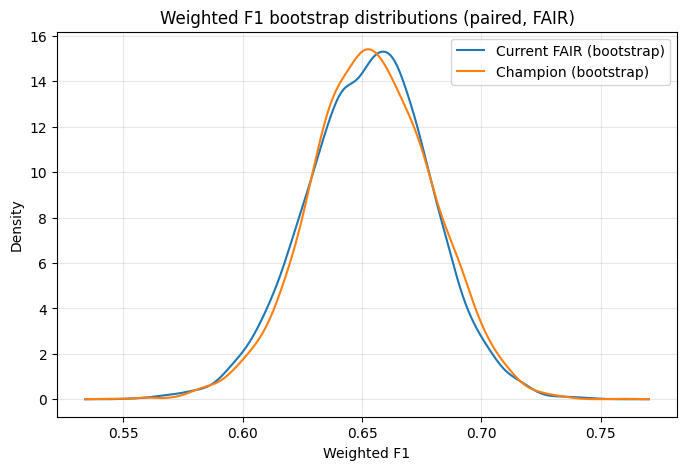

In [17]:
# =========================
# FAIR XGBoost_gbtree retrain + compare to champion artifacts
# - Removes overlap between OUR train set and champion X_test (prevents leakage)
# - Tunes XGB on the filtered train set (CV weighted F1)
# - Evaluates on champion X_test (same 345 rows as champion outputs)
# - Uses champion y_true + y_pred from MLflow artifact, no re-running champion model
# =========================

import numpy as np
import pandas as pd
import hashlib
import time
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score

# --- Preconditions ---
if "champ_X_test" not in globals() or "champ_pred_df" not in globals():
    raise NameError("Need champ_X_test and champ_pred_df. Download champion X_test_inputs.csv and test_outputs_predictions.csv first.")
if "le" not in globals() or "y_train_enc" not in globals():
    raise NameError("Need LabelEncoder le and y_train_enc for XGBoost.")
if "cv" not in globals():
    raise NameError("Need cv (StratifiedKFold) defined.")

# --- Fingerprinting to remove overlap ---
def row_fingerprint(df: pd.DataFrame) -> pd.Series:
    df2 = df.copy()
    for c in df2.columns:
        if pd.api.types.is_float_dtype(df2[c]):
            df2[c] = df2[c].round(10)
    return df2.astype(str).agg("|".join, axis=1).apply(lambda s: hashlib.md5(s.encode()).hexdigest())

# Ensure same columns/order
champ_X_test_aligned = champ_X_test.reindex(columns=X_train.columns)

fp_ch = set(row_fingerprint(champ_X_test_aligned))
fp_train = row_fingerprint(X_train)
keep_mask = ~fp_train.isin(fp_ch)

X_train_fair = X_train.loc[keep_mask].copy()
y_train_fair_enc = y_train_enc[keep_mask.values]  # array aligned with X_train rows

removed = int((~keep_mask).sum())
print("Original X_train:", X_train.shape)
print("Fair X_train:", X_train_fair.shape)
print("Removed overlap rows:", removed, f"({removed/len(X_train):.1%} of train)")

# --- Define XGB model + param space (same as your original gbtree cell) ---
xgb_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="multi:softprob",
        num_class=len(le.classes_),
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=600 if FAST_MODE else 1500,
        verbosity=0,
    ))
])

param_xgb_tree = {
    "xgb__max_depth": [3, 4, 5, 6, 8],
    "xgb__learning_rate": np.logspace(-2.1, -0.7, 18),
    "xgb__subsample": [0.6, 0.8, 1.0],
    "xgb__colsample_bytree": [0.6, 0.8, 1.0],
    "xgb__min_child_weight": [1, 2, 5, 10],
    "xgb__gamma": [0.0, 0.1, 0.3, 1.0],
    "xgb__reg_alpha": np.logspace(-4, -0.5, 10),
    "xgb__reg_lambda": np.logspace(-2, 1, 10),
}

# Robust scorer for weighted F1
from sklearn.metrics import make_scorer
def safe_weighted_f1(y_true, y_pred):
    return f1_score(y_true, le.inverse_transform(y_pred.astype(int)), average="weighted", zero_division=0)

# NOTE: In CV, XGB predicts encoded ints, so scoring must decode to strings.
# We'll implement scoring by custom scorer on encoded preds:
def weighted_f1_on_encoded(y_true_enc, y_pred_enc):
    yt = le.inverse_transform(y_true_enc.astype(int))
    yp = le.inverse_transform(y_pred_enc.astype(int))
    return f1_score(yt, yp, average="weighted", zero_division=0)

f1_weighted_encoded = make_scorer(weighted_f1_on_encoded)

search = RandomizedSearchCV(
    estimator=xgb_tree,
    param_distributions=param_xgb_tree,
    n_iter=N_ITER,
    scoring=f1_weighted_encoded,
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score=0.0,
)

t0 = time.perf_counter()
search.fit(X_train_fair, y_train_fair_enc)
t1 = time.perf_counter()

best_xgb_fair = search.best_estimator_
print("\n==== XGBoost_gbtree FAIR retrain ====")
print("CV weighted_f1 (encoded->decoded):", float(search.best_score_))
print("Best params:", search.best_params_)
print("Seconds:", float(t1 - t0))

# --- Evaluate on champion X_test (paired set) ---
y_true_ch = champ_pred_df["y_true"].astype(str).reset_index(drop=True).values
y_pred_ch = champ_pred_df["y_pred"].astype(str).reset_index(drop=True).values

pred_cur_fair = le.inverse_transform(best_xgb_fair.predict(champ_X_test_aligned).astype(int))

wf1_cur = f1_score(y_true_ch, pred_cur_fair, average="weighted", zero_division=0)
wf1_ch  = f1_score(y_true_ch, y_pred_ch, average="weighted", zero_division=0)

print("\nFair evaluation on champion X_test (345 rows):")
print("Current FAIR weighted_f1:", float(wf1_cur))
print("Champion weighted_f1:", float(wf1_ch))
print("Delta (cur - champ):", float(wf1_cur - wf1_ch))

# --- Paired bootstrap CI of difference ---
B = 5000
rng = np.random.default_rng(42)
n = len(y_true_ch)
cur_samples = np.empty(B, dtype=float)
ch_samples = np.empty(B, dtype=float)

for b in range(B):
    idx = rng.integers(0, n, size=n)
    cur_samples[b] = f1_score(y_true_ch[idx], pred_cur_fair[idx], average="weighted", zero_division=0)
    ch_samples[b]  = f1_score(y_true_ch[idx], y_pred_ch[idx], average="weighted", zero_division=0)

diff = cur_samples - ch_samples
ci = (float(np.quantile(diff, 0.025)), float(np.quantile(diff, 0.975)))

print("\nPaired bootstrap diff (cur - champ):")
print("Mean diff:", float(diff.mean()))
print("95% CI:", ci)

# KDE plot (optional)
try:
    from scipy.stats import gaussian_kde
    xs = np.linspace(min(cur_samples.min(), ch_samples.min()) - 0.01,
                     max(cur_samples.max(), ch_samples.max()) + 0.01, 400)
    plt.figure(figsize=(8, 5))
    plt.plot(xs, gaussian_kde(cur_samples)(xs), label="Current FAIR (bootstrap)")
    plt.plot(xs, gaussian_kde(ch_samples)(xs), label="Champion (bootstrap)")
    plt.title("Weighted F1 bootstrap distributions (paired, FAIR)")
    plt.xlabel("Weighted F1")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
except Exception:
    pass

### Paired bootstrap + paired t-test + KDE plot

In [82]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd
import hashlib

def row_fingerprint(df: pd.DataFrame) -> pd.Series:
    df2 = df.copy()
    for c in df2.columns:
        if pd.api.types.is_float_dtype(df2[c]):
            df2[c] = df2[c].round(10)
    return df2.astype(str).agg("|".join, axis=1).apply(lambda s: hashlib.md5(s.encode()).hexdigest())

# Build overlap mask
fp_ch = set(row_fingerprint(champ_X_test))
fp_train = row_fingerprint(X_train)
keep_mask = ~fp_train.isin(fp_ch)

X_train_fair = X_train.loc[keep_mask].copy()
y_train_fair_enc = y_train_enc[keep_mask.values]

print("Original X_train:", X_train.shape)
print("Fair X_train:", X_train_fair.shape)
print("Removed overlap rows:", int((~keep_mask).sum()))

# Refit using best gbtree params from your best run (row_xgb_tree)
best_params = row_xgb_tree["best_params"]

xgb_fair = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="multi:softprob",
        num_class=len(le.classes_),
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_estimators=600 if FAST_MODE else 1500,
        verbosity=0,
    ))
])

xgb_fair.set_params(**best_params)
xgb_fair.fit(X_train_fair, y_train_fair_enc)

pred_current_fair = le.inverse_transform(xgb_fair.predict(champ_X_test).astype(int))
y_true_champ = champ_pred_df["y_true"].astype(str).values

wf1_fair = f1_score(y_true_champ, pred_current_fair, average="weighted", zero_division=0)
print("\nFAIR weighted_f1 on champion X_test:", float(wf1_fair))

Original X_train: (1381, 38)
Fair X_train: (1141, 38)
Removed overlap rows: 240

FAIR weighted_f1 on champion X_test: 0.6532016533680919


PAIRED comparison on champion X_test
Rows: 345
Current model label: XGBoost_gbtree

Bootstrap weighted F1 (paired):
  Current mean:  0.652680
  Champion mean: 0.654065
  Mean diff (cur - champ): -0.001385
  95% CI of diff: [-0.038093, +0.035117]

Paired t-test on bootstrap samples (informational):
  t = -5.2354, p = 1.7136e-07


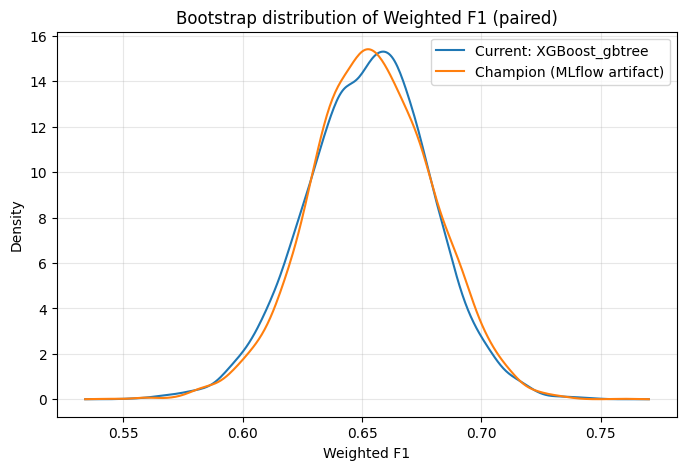

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# scipy optional
try:
    from scipy.stats import ttest_rel, gaussian_kde
    SCIPY_OK = True
except Exception:
    SCIPY_OK = False

# Labels for plotting
model_label = globals().get("top_model_name", "Current model")

# --- Build paired data on champion's test set ---
if "champ_pred_df" not in globals():
    raise NameError("champ_pred_df not found. Download champion artifacts first.")
if "pred_current_fair" not in globals():
    raise NameError("pred_current_fair not found. Predict current model on champ_X_test first.")

champ_df = champ_pred_df.copy()
champ_df["y_true"] = champ_df["y_true"].astype(str)
champ_df["y_pred"] = champ_df["y_pred"].astype(str)

y_true = champ_df["y_true"].reset_index(drop=True).values
y_pred_ch = champ_df["y_pred"].reset_index(drop=True).values
y_pred_cur = pd.Series(pred_current_fair).astype(str).reset_index(drop=True).values

if len(y_true) != len(y_pred_cur):
    raise ValueError(
        f"Paired comparison requires same length.\n"
        f"Champion rows={len(y_true)} vs pred_current_fair={len(y_pred_cur)}.\n"
        f"Make sure pred_current_fair = model.predict(champ_X_test) decoded."
    )

print("PAIRED comparison on champion X_test")
print("Rows:", len(y_true))
print("Current model label:", model_label)

# --- Paired bootstrap ---
B = 5000
rng = np.random.default_rng(42)
n = len(y_true)

cur_samples = np.empty(B, dtype=float)
ch_samples = np.empty(B, dtype=float)

for b in range(B):
    idx = rng.integers(0, n, size=n)
    cur_samples[b] = f1_score(y_true[idx], y_pred_cur[idx], average="weighted", zero_division=0)
    ch_samples[b]  = f1_score(y_true[idx], y_pred_ch[idx],  average="weighted", zero_division=0)

diff = cur_samples - ch_samples
diff_mean = float(diff.mean())
ci = (float(np.quantile(diff, 0.025)), float(np.quantile(diff, 0.975)))

print("\nBootstrap weighted F1 (paired):")
print(f"  Current mean:  {cur_samples.mean():.6f}")
print(f"  Champion mean: {ch_samples.mean():.6f}")
print(f"  Mean diff (cur - champ): {diff_mean:+.6f}")
print(f"  95% CI of diff: [{ci[0]:+.6f}, {ci[1]:+.6f}]")

# --- Paired t-test (note: bootstrap samples are not independent; CI is usually the main result)
if SCIPY_OK:
    t_stat, p_val = ttest_rel(cur_samples, ch_samples)
    print("\nPaired t-test on bootstrap samples (informational):")
    print(f"  t = {t_stat:.4f}, p = {p_val:.6g}")
else:
    print("\nSciPy not available -> skipping paired t-test p-value.")

# --- KDE plot ---
plt.figure(figsize=(8, 5))
if SCIPY_OK:
    xs = np.linspace(min(cur_samples.min(), ch_samples.min()) - 0.01,
                     max(cur_samples.max(), ch_samples.max()) + 0.01, 400)
    plt.plot(xs, gaussian_kde(cur_samples)(xs), label=f"Current: {model_label}")
    plt.plot(xs, gaussian_kde(ch_samples)(xs),  label="Champion (MLflow artifact)")
else:
    plt.hist(cur_samples, bins=40, density=True, alpha=0.5, label=f"Current: {model_label}")
    plt.hist(ch_samples,  bins=40, density=True, alpha=0.5, label="Champion (MLflow artifact)")

plt.title("Bootstrap distribution of Weighted F1 (paired)")
plt.xlabel("Weighted F1")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

try:
    from scipy.stats import gaussian_kde
    SCIPY_OK = True
except Exception:
    SCIPY_OK = False

y_true = champ_pred_df["y_true"].astype(str).reset_index(drop=True).values
y_pred_ch = champ_pred_df["y_pred"].astype(str).reset_index(drop=True).values
y_pred_cur = pd.Series(pred_current_fair).astype(str).reset_index(drop=True).values

B = 5000
rng = np.random.default_rng(42)
n = len(y_true)

cur_samples = np.empty(B, dtype=float)
ch_samples = np.empty(B, dtype=float)

for b in range(B):
    idx = rng.integers(0, n, size=n)
    cur_samples[b] = f1_score(y_true[idx], y_pred_cur[idx], average="weighted", zero_division=0)
    ch_samples[b]  = f1_score(y_true[idx], y_pred_ch[idx],  average="weighted", zero_division=0)

diff = cur_samples - ch_samples
diff_mean = float(diff.mean())
ci = (float(np.quantile(diff, 0.025)), float(np.quantile(diff, 0.975)))

print("PAIRED (fair refit) bootstrap weighted F1:")
print(f"  Current mean:  {cur_samples.mean():.6f}")
print(f"  Champion mean: {ch_samples.mean():.6f}")
print(f"  Mean diff:     {diff_mean:+.6f}")
print(f"  95% CI diff:   [{ci[0]:+.6f}, {ci[1]:+.6f}]")

plt.figure(figsize=(8, 5))
if SCIPY_OK:
    xs = np.linspace(min(cur_samples.min(), ch_samples.min()) - 0.01,
                     max(cur_samples.max(), ch_samples.max()) + 0.01, 400)
    plt.plot(xs, gaussian_kde(cur_samples)(xs), label="Current (fair refit)")
    plt.plot(xs, gaussian_kde(ch_samples)(xs),  label="Champion (artifact)")
else:
    plt.hist(cur_samples, bins=40, density=True, alpha=0.5, label="Current (fair refit)")
    plt.hist(ch_samples,  bins=40, density=True, alpha=0.5, label="Champion (artifact)")

plt.title("Bootstrap distribution of Weighted F1 (paired, no leakage)")
plt.xlabel("Weighted F1")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

NameError: name 'pred_current_fair' is not defined

In [ ]:
# =========================
# FINAL: Log + Register + Promote TOP model (by test_weighted_f1) to MLflow
# - Logs model, metrics, params, X_test inputs, predictions+probas, metadata JSON
# - Registers model under weakest_link_model
# - Promotes to alias "champion" (or Production stage fallback)
# =========================

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime

import mlflow
import mlflow.sklearn
from mlflow.models.signature import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.metrics import f1_score, log_loss

REGISTERED_MODEL_NAME = "weakest_link_model"
artifact_dir = "mlflow_champion_artifacts"
os.makedirs(artifact_dir, exist_ok=True)

client = MlflowClient()

# ---------- 1) Determine the top model name from your leaderboard ----------
# If your leaderboard variable is named differently, change `lb` below.
if "lb" in globals() and isinstance(lb, pd.DataFrame) and not lb.empty:
    top_row = lb.sort_values("test_weighted_f1", ascending=False).iloc[0]
    top_model_name = str(top_row["model"])
    top_test_wf1 = float(top_row["test_weighted_f1"])
    top_cv_wf1 = float(top_row["cv_weighted_f1"]) if "cv_weighted_f1" in top_row else None
    top_seconds = float(top_row["seconds"]) if "seconds" in top_row else None
else:
    # Fallback: build from COMP_RESULTS if lb not present
    if "COMP_RESULTS" not in globals() or len(COMP_RESULTS) == 0:
        raise RuntimeError("No leaderboard (lb) and no COMP_RESULTS found. Run tuning cells first.")
    tmp = pd.DataFrame([{
        "model": r["model"],
        "cv_weighted_f1": r["cv_weighted_f1"],
        "test_weighted_f1": r["test_weighted_f1"],
        "seconds": r["seconds"],
        "best_params": r["best_params"],
    } for r in COMP_RESULTS]).sort_values("test_weighted_f1", ascending=False).reset_index(drop=True)
    top_row = tmp.iloc[0]
    top_model_name = str(top_row["model"])
    top_test_wf1 = float(top_row["test_weighted_f1"])
    top_cv_wf1 = float(top_row["cv_weighted_f1"])
    top_seconds = float(top_row["seconds"])

print("Top model selected:", top_model_name, "| test_weighted_f1 =", top_test_wf1)

# ---------- 2) Get the fitted estimator object + best params ----------
# Works if you used COMP_RESULTS from the split-cell approach (recommended)
best_estimator = None
best_params = None

if "COMP_RESULTS" in globals() and len(COMP_RESULTS) > 0:
    match = [r for r in COMP_RESULTS if r["model"] == top_model_name]
    if match:
        # If duplicates exist, pick the one with highest test_weighted_f1
        match = sorted(match, key=lambda r: r.get("test_weighted_f1", -1), reverse=True)
        best_estimator = match[0]["best_estimator"]
        best_params = match[0]["best_params"]

# If you used a different store, you can manually set best_estimator here:
if best_estimator is None:
    raise RuntimeError("Could not find the fitted best_estimator for top model. Ensure COMP_RESULTS stores best_estimator.")

# ---------- 3) Predict on test set (handle XGBoost label encoding) ----------
is_xgb = top_model_name.startswith("XGBoost")
pred = None
proba = None

# XGBoost models in your notebook were trained using y_train_enc and decoded with le.
# For scoring + exports we need string preds aligned with y_test.
if is_xgb and "le" in globals():
    pred_enc = best_estimator.predict(X_test).astype(int)
    pred = le.inverse_transform(pred_enc)
    if hasattr(best_estimator, "predict_proba"):
        proba = best_estimator.predict_proba(X_test)  # shape (n, K) where K = num_class
else:
    pred = best_estimator.predict(X_test)
    if hasattr(best_estimator, "predict_proba"):
        proba = best_estimator.predict_proba(X_test)

# ---------- 4) Compute metrics (robust) ----------
# Use class list based on y_test for safety (prevents mismatch)
classes_for_ll = sorted(pd.unique(y_test))

metrics = {
    "accuracy": float((pd.Series(pred).reset_index(drop=True) == pd.Series(y_test).reset_index(drop=True)).mean()),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, pred)),
    "macro_f1": float(f1_score(y_test, pred, average="macro", zero_division=0)),
    "weighted_f1": float(f1_score(y_test, pred, average="weighted", zero_division=0)),
}

# log_loss only if proba is consistent
if proba is not None and proba.shape[1] == len(classes_for_ll):
    metrics["log_loss"] = float(log_loss(y_test, proba, labels=classes_for_ll))
else:
    metrics["log_loss"] = float("nan")

print("Metrics on this notebook split:", metrics)

# ---------- 5) Save inputs + outputs as artifacts ----------
X_test_csv = os.path.join(artifact_dir, "X_test_inputs.csv")
pd.DataFrame(X_test, columns=X_test.columns).to_csv(X_test_csv, index=False)

pred_df = pd.DataFrame({
    "y_true": pd.Series(y_test).reset_index(drop=True),
    "y_pred": pd.Series(pred).reset_index(drop=True),
})

# Probabilities: only if available and compatible
if proba is not None and proba.shape[1] == len(classes_for_ll):
    proba_cols = [f"proba_{c}" for c in classes_for_ll]
    proba_df = pd.DataFrame(proba, columns=proba_cols)
    pred_df = pd.concat([pred_df, proba_df], axis=1)

outputs_csv = os.path.join(artifact_dir, "test_outputs_predictions.csv")
pred_df.to_csv(outputs_csv, index=False)

# Metadata
meta = {
    "task": "WeakestLink classification",
    "objective": "maximize_weighted_f1",
    "registered_model_name": REGISTERED_MODEL_NAME,
    "top_model_name": top_model_name,
    "created_utc": datetime.utcnow().isoformat(),
    "random_seed": int(RANDOM_SEED),
    "cv_weighted_f1": float(top_cv_wf1) if top_cv_wf1 is not None else None,
    "test_weighted_f1_from_leaderboard": float(top_test_wf1),
    "test_metrics_recomputed": metrics,
    "seconds_tuning": float(top_seconds) if top_seconds is not None else None,
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "n_features": int(X_train.shape[1]),
    "feature_cols": list(X_train.columns),
    "classes_dataset": [str(c) for c in classes_for_ll],
    "best_params": best_params,
    "notes": "Model logged+registered from competition notebook. Includes X_test inputs and outputs artifacts.",
}
meta_json = os.path.join(artifact_dir, "champion_metadata.json")
with open(meta_json, "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

# ---------- 6) Log to MLflow + Register ----------
with mlflow.start_run(run_name=f"CHAMPION_{top_model_name}_weightedF1") as run:
    run_id = run.info.run_id

    # Tags aligned with your previous champion notebook
    mlflow.set_tag("task", "classification")
    mlflow.set_tag("project_component", "weakest_link")
    mlflow.set_tag("objective", "weighted_f1")
    mlflow.set_tag("model_key", top_model_name)
    mlflow.set_tag("champion_candidate", "true")
    mlflow.set_tag("registered_model_name", REGISTERED_MODEL_NAME)

    # Log metrics
    mlflow.log_metrics(metrics)
    if top_cv_wf1 is not None:
        mlflow.log_metric("cv_weighted_f1", float(top_cv_wf1))
    if top_seconds is not None:
        mlflow.log_metric("tuning_seconds", float(top_seconds))

    # Log params
    if best_params is not None:
        # best_params may contain numpy types -> convert
        clean_params = {k: (float(v) if isinstance(v, (np.floating,)) else v) for k, v in best_params.items()}
        mlflow.log_params(clean_params)

    # Log artifacts
    mlflow.log_artifact(X_test_csv)
    mlflow.log_artifact(outputs_csv)
    mlflow.log_artifact(meta_json)

    # Signature
    X_example = X_train.head(20)
    # For XGB trained on encoded y, predict returns encoded ints; signature is still fine as output example
    y_example = best_estimator.predict(X_example)
    signature = infer_signature(X_example, y_example)

    # Log + Register model to registry under weakest_link_model
    model_info = mlflow.sklearn.log_model(
        sk_model=best_estimator,
        name="model",
        signature=signature,
        input_example=X_example,
        registered_model_name=REGISTERED_MODEL_NAME,
    )

print("\nLogged + registered top model.")
print("Run ID:", run_id)
print("Top model:", top_model_name)
print("Test weighted_f1:", metrics["weighted_f1"])

# ---------- 7) Promote to champion alias (fallback to Production stage) ----------
versions = client.search_model_versions(f"name='{REGISTERED_MODEL_NAME}'")
this_run_versions = [v for v in versions if v.run_id == run_id]
if not this_run_versions:
    raise RuntimeError("Could not find a registered model version created by this run.")
version = max(int(v.version) for v in this_run_versions)

promoted = False
try:
    client.set_registered_model_alias(REGISTERED_MODEL_NAME, "champion", str(version))
    promoted = True
    print(f"Set alias 'champion' -> {REGISTERED_MODEL_NAME} v{version}")
except Exception as e_alias:
    try:
        client.transition_model_version_stage(
            name=REGISTERED_MODEL_NAME,
            version=version,
            stage="Production",
            archive_existing_versions=True
        )
        promoted = True
        print(f"Transitioned {REGISTERED_MODEL_NAME} v{version} to Production (archived previous).")
    except Exception as e_stage:
        print("Could not set alias or transition stage automatically.")
        print("Alias error:", repr(e_alias))
        print("Stage error:", repr(e_stage))